   Beban   Temp    Skor  Kategori
   45000      8   10.83  Very Low
   72000     19   40.72  Normal
   85000     25   67.01  High
  120000     33   90.71  Critical Peak
   60000     30   53.88  Normal
  100000      5    70.0  High


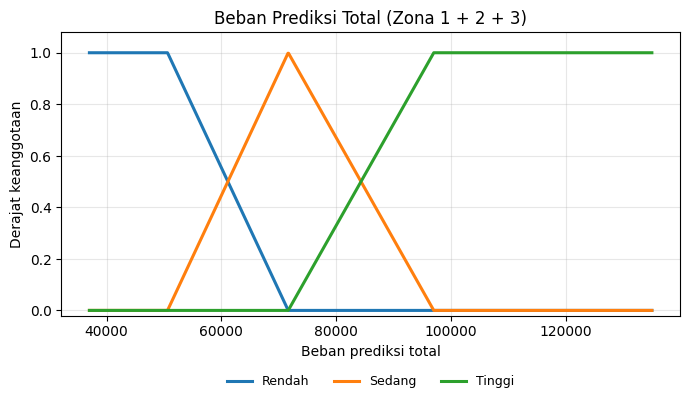

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

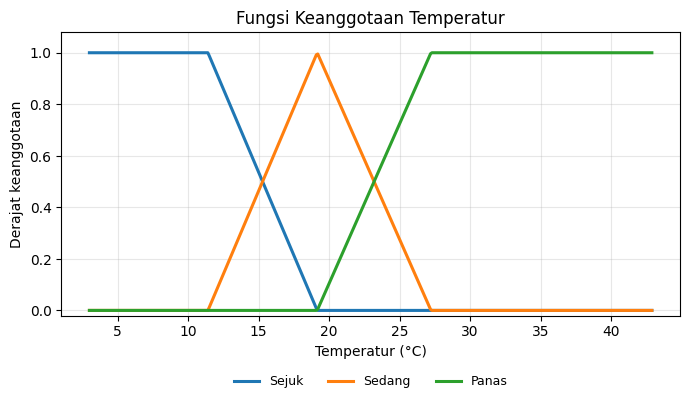

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

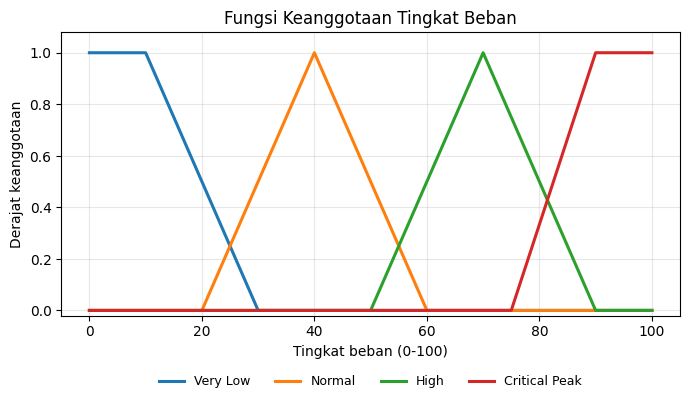

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
!pip install scikit-fuzzy -q
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

# Variabel
total = ctrl.Antecedent(np.arange(37000, 135001, 100), 'Beban Prediksi Total')
suhu  = ctrl.Antecedent(np.arange(3, 43, 0.1), 'Temperatur')
level = ctrl.Consequent(np.arange(0, 100.01, 0.5), 'Tingkat Beban')

# Membership function (dari persentil data training)
total['Rendah'] = fuzz.trapmf(total.universe, [37000, 37000, 50615, 71642])
total['Sedang'] = fuzz.trimf(total.universe,  [50615, 71642, 96996])
total['Tinggi'] = fuzz.trapmf(total.universe, [71642, 96996, 135000, 135000])

suhu['Sejuk']  = fuzz.trapmf(suhu.universe, [3, 3, 11.41, 19.16])
suhu['Sedang'] = fuzz.trimf(suhu.universe,  [11.41, 19.16, 27.23])
suhu['Panas']  = fuzz.trapmf(suhu.universe, [19.16, 27.23, 43, 43])

level['Very Low']      = fuzz.trapmf(level.universe, [0, 0, 10, 30])
level['Normal']        = fuzz.trimf(level.universe,  [20, 40, 60])
level['High']          = fuzz.trimf(level.universe,  [50, 70, 90])
level['Critical Peak'] = fuzz.trapmf(level.universe, [75, 90, 100, 100])

# 9 aturan (sesuai Tabel 2.2)
rules = [
    ctrl.Rule(total['Rendah'] & suhu['Sejuk'],  level['Very Low']),
    ctrl.Rule(total['Rendah'] & suhu['Sedang'], level['Very Low']),
    ctrl.Rule(total['Rendah'] & suhu['Panas'],  level['Normal']),
    ctrl.Rule(total['Sedang'] & suhu['Sejuk'],  level['Normal']),
    ctrl.Rule(total['Sedang'] & suhu['Sedang'], level['Normal']),
    ctrl.Rule(total['Sedang'] & suhu['Panas'],  level['High']),
    ctrl.Rule(total['Tinggi'] & suhu['Sejuk'],  level['High']),
    ctrl.Rule(total['Tinggi'] & suhu['Sedang'], level['High']),
    ctrl.Rule(total['Tinggi'] & suhu['Panas'],  level['Critical Peak']),
]
sistem = ctrl.ControlSystem(rules)

def klasifikasi(beban, temp):
    sim = ctrl.ControlSystemSimulation(sistem)
    sim.input['Beban Prediksi Total'] = beban
    sim.input['Temperatur'] = temp
    sim.compute()
    n = sim.output['Tingkat Beban']
    if n < 25: k = 'Very Low'
    elif n < 55: k = 'Normal'
    elif n < 80: k = 'High'
    else: k = 'Critical Peak'
    return round(n, 2), k

# Uji skenario
skenario = [(45000, 8), (72000, 19), (85000, 25), (120000, 33), (60000, 30), (100000, 5)]
print(f"{'Beban':>8} {'Temp':>6} {'Skor':>7}  Kategori")
for b, t in skenario:
    s, k = klasifikasi(b, t)
    print(f"{b:>8} {t:>6} {s:>7}  {k}")

# ===== 3 GAMBAR TERPISAH =====
from google.colab import files

daftar = [
    (total, 'Beban Prediksi Total (Zona 1 + 2 + 3)', 'Beban prediksi total', 'gambar_2_4a_membership_beban.png'),
    (suhu,  'Fungsi Keanggotaan Temperatur',          'Temperatur (°C)',      'gambar_2_4b_membership_temperatur.png'),
    (level, 'Fungsi Keanggotaan Tingkat Beban',       'Tingkat beban (0-100)', 'gambar_2_4c_membership_tingkat_beban.png'),
]

for v, judul, xlabel, nama_file in daftar:
    fig, a = plt.subplots(figsize=(7, 4.2))
    for nama, term in v.terms.items():
        a.plot(v.universe, term.mf, label=nama, linewidth=2.2)
    a.set_title(judul)
    a.set_xlabel(xlabel)
    a.set_ylabel('Derajat keanggotaan')
    a.set_ylim(-0.02, 1.08)
    a.grid(alpha=.3)
    a.legend(loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=4, fontsize=9, frameon=False)
    plt.tight_layout()
    plt.savefig(nama_file, dpi=200, bbox_inches='tight')
    plt.show()
    files.download(nama_file)

In [10]:
# 1. Unduh dataset UCI (ID 849)
!pip install ucimlrepo scikit-fuzzy -q
from ucimlrepo import fetch_ucirepo
import pandas as pd

data = fetch_ucirepo(id=849)
df = data.data.original.copy()
print("Bentuk data:", df.shape)          # harusnya (52416, 9)

# Bersihkan nama kolom dari spasi ganda atau spasi di awal/akhir
df.columns = df.columns.str.strip().str.replace(r'\s+', ' ', regex=True)

# Cari kolom secara otomatis
def cari(kata):
    return [c for c in df.columns if kata.lower() in c.lower()][0]

col_dt   = cari('datetime')
col_temp = cari('temperature')
zones    = [cari('zone 1'), cari('zone 2'), cari('zone 3')]
print("Kolom zona yang dipakai:", zones)

# 2. Siapkan data (urut kronologis)
df[col_dt] = pd.to_datetime(df[col_dt])
df = df.sort_values(col_dt).reset_index(drop=True)
df['Total'] = df[zones].sum(axis=1)

# 3. Ambil data training saja (70% pertama) agar tidak bocor
train = df.iloc[:int(len(df) * 0.70)]
print("Jumlah data training (kira-kira):", len(train))

# 4. Hitung batas untuk membership function fuzzy
print("\n=== BATAS FUZZY (dari data training) ===")
for nama, col in [('Total', 'Total'), ('Temperature', col_temp)]:
    q = train[col].quantile([0.10, 0.50, 0.90]).round(2)
    print(f"{nama}: P10={q[0.10]}, P50={q[0.50]}, P90={q[0.90]}, "
          f"min={round(train[col].min(), 2)}, max={round(train[col].max(), 2)}")

Bentuk data: (52416, 9)
Kolom zona yang dipakai: ['Zone 1 Power Consumption', 'Zone 2 Power Consumption', 'Zone 3 Power Consumption']
Jumlah data training (kira-kira): 36691

=== BATAS FUZZY (dari data training) ===
Total: P10=50614.77, P50=71642.21, P90=96995.99, min=37436.22, max=134208.15
Temperature: P10=11.41, P50=19.16, P90=27.23, min=3.25, max=40.01
